In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
data_path = Path("../data/sales_data.csv")
df = pd.read_csv(data_path)
df["revenue"] = df["units_sold"] * df["unit_price"]
print("REPORTING DATA SUMMARY")
print("----------------------")
print("Total records:", len(df))
print("Total revenue: ₹", df["revenue"].sum())
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

REPORTING DATA SUMMARY
----------------------
Total records: 10
Total revenue: ₹ 21660
Missing values: 0
Duplicate rows: 0


In [2]:
product_report = (df.groupby("product").agg(units_sold=("units_sold", "sum"),revenue=("revenue", "sum")).sort_values("revenue", ascending=False))
print("PRODUCT PERFORMANCE")
display(product_report)
category_report = (df.groupby("category").agg(units_sold=("units_sold", "sum"),revenue=("revenue", "sum")).sort_values("revenue", ascending=False))
print("CATEGORY PERFORMANCE")
display(category_report)
region_report = (df.groupby("region").agg(units_sold=("units_sold", "sum"),revenue=("revenue", "sum")).sort_values("revenue", ascending=False))
print("REGION PERFORMANCE")
display(region_report)

PRODUCT PERFORMANCE


,units_sold,revenue
product,,
Keyboard,5,7495
Mouse,8,6392
Desk Lamp,3,3897
Water Bottle,4,1596
Notebook,22,1320
Pen Set,8,960


CATEGORY PERFORMANCE


,units_sold,revenue
category,,
Electronics,13,13887
Home,7,5493
Stationery,30,2280


REGION PERFORMANCE


,units_sold,revenue
region,,
East,17,6693
South,7,6593
North,12,4656
West,14,3718


In [3]:
print("KEY FINDINGS")
print("------------")
print("Top product:",product_report.index[0],"| Revenue: ₹",product_report.iloc[0]["revenue"])
print("Top category:",category_report.index[0],"| Revenue: ₹",category_report.iloc[0]["revenue"])
print("Top region:",region_report.index[0],"| Revenue: ₹",region_report.iloc[0]["revenue"])
print("\nTotal dataset revenue: ₹", df["revenue"].sum())

KEY FINDINGS
------------
Top product: Keyboard | Revenue: ₹ 7495
Top category: Electronics | Revenue: ₹ 13887
Top region: East | Revenue: ₹ 6693

Total dataset revenue: ₹ 21660


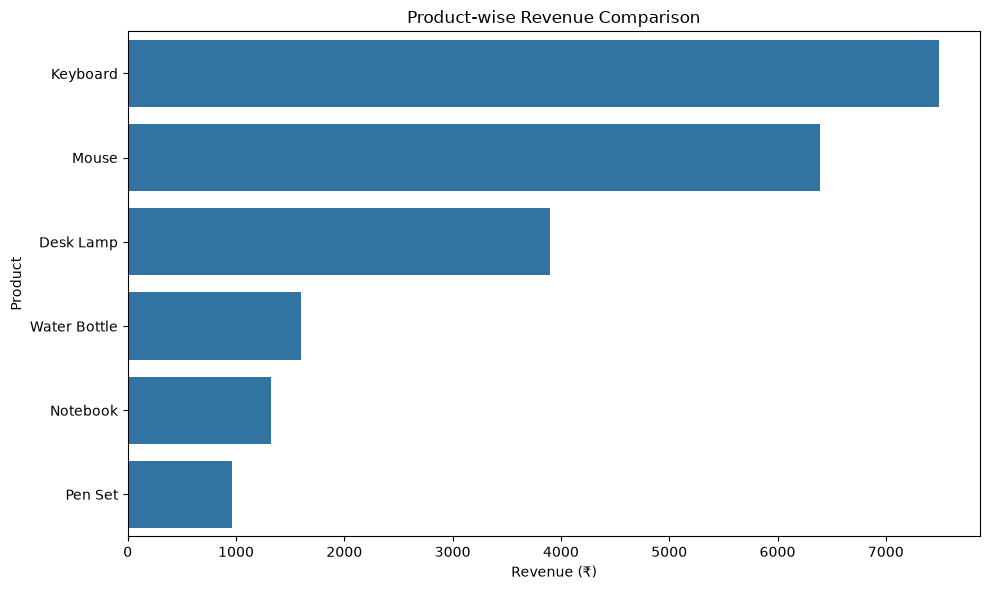

In [4]:
from pathlib import Path
output_dir = Path("charts")
output_dir.mkdir(exist_ok=True)
product_chart = product_report.reset_index()
plt.figure(figsize=(10, 6))
sns.barplot(data=product_chart,x="revenue",y="product")
plt.title("Product-wise Revenue Comparison")
plt.xlabel("Revenue (₹)")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(output_dir / "product_revenue_report.png",dpi=300,bbox_inches="tight")
plt.show()

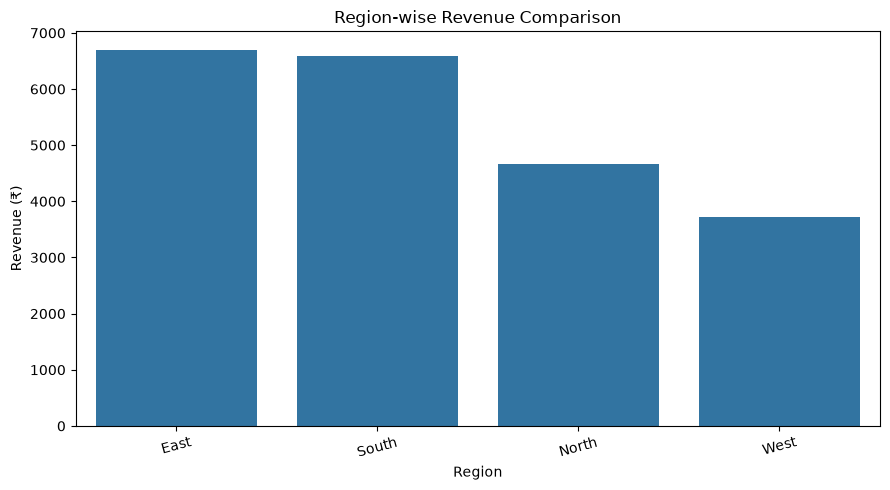

In [5]:
region_chart = region_report.reset_index()
plt.figure(figsize=(9, 5))
sns.barplot(data=region_chart,x="region",y="revenue")
plt.title("Region-wise Revenue Comparison")
plt.xlabel("Region")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(output_dir / "region_revenue_report.png",dpi=300,bbox_inches="tight")
plt.show()

In [6]:
top_product = product_report.index[0]
top_product_revenue = product_report.iloc[0]["revenue"]
top_category = category_report.index[0]
top_category_revenue = category_report.iloc[0]["revenue"]
top_region = region_report.index[0]
top_region_revenue = region_report.iloc[0]["revenue"]
total_revenue = df["revenue"].sum()
print("PROJECT 5: REPORTING AND INSIGHT GENERATION")
print("=" * 50)
print(f"Total revenue: ₹{total_revenue:,.2f}")
print(f"Highest-revenue product: {top_product} "f"(₹{top_product_revenue:,.2f})")
print(f"Highest-revenue category: {top_category} "f"(₹{top_category_revenue:,.2f})")
print(f"Highest-revenue region: {top_region} "f"(₹{top_region_revenue:,.2f})")
print("\nREPORTING NOTE")
print("These findings describe a synthetic sample dataset. ""They should not be treated as evidence of real-world market demand or business performance.")

PROJECT 5: REPORTING AND INSIGHT GENERATION
Total revenue: ₹21,660.00
Highest-revenue product: Keyboard (₹7,495.00)
Highest-revenue category: Electronics (₹13,887.00)
Highest-revenue region: East (₹6,693.00)

REPORTING NOTE
These findings describe a synthetic sample dataset. They should not be treated as evidence of real-world market demand or business performance.


In [7]:
recommendations = []
top_product = product_report.index[0]
top_category = category_report.index[0]
top_region = region_report.index[0]
recommendations.append(f"Product performance: Review the sales and revenue "f"patterns for {top_product}. Investigate whether its "f"performance is consistent across additional periods.")
recommendations.append(f"Category performance: Examine the factors contributing "f"to the revenue generated by the {top_category} category "f"before making inventory or marketing decisions.")
recommendations.append(f"Regional performance: Investigate the sales mix and "f"customer demand in {top_region}. Validate the pattern "f"with a larger, real-world dataset.")
print("ACTIONABLE RECOMMENDATIONS")
print("=" * 40)
for number, recommendation in enumerate(recommendations, start=1):
    print(f"{number}. {recommendation}\n")

ACTIONABLE RECOMMENDATIONS
1. Product performance: Review the sales and revenue patterns for Keyboard. Investigate whether its performance is consistent across additional periods.

2. Category performance: Examine the factors contributing to the revenue generated by the Electronics category before making inventory or marketing decisions.

3. Regional performance: Investigate the sales mix and customer demand in East. Validate the pattern with a larger, real-world dataset.



EXECUTIVE SUMMARY

This project focuses on reporting and insight generation using a synthetic sales dataset. Python, Pandas, Matplotlib, and Seaborn were used to summarize revenue performance across products, categories, and regions.
The analysis calculated total revenue using units sold and unit price, compared performance across groups, and presented the results through visualizations.
The highest-revenue product was [insert product from output], the highest-revenue category was [insert category from output], and the highest-revenue region was [insert region from output].
These findings describe the supplied sample dataset only. Because the dataset is synthetic and limited in size, the results should be validated using larger, real-world data before making business decisions.

CONCLUSION

This project demonstrated how Python can transform sales data into structured reports and interpretable insights. Using Pandas, the dataset was summarized across products, categories, and regions, while Matplotlib and Seaborn were used to communicate revenue comparisons visually.
The analysis helped identify the highest-revenue product, category, and region within the supplied sample. Recommendations were framed around further investigation and validation rather than unsupported business assumptions.
Since the dataset is synthetic and contains a limited number of records, the findings are illustrative rather than representative of actual business performance. Future analysis could use a larger dataset covering multiple time periods, costs, profit margins, and customer information.
Overall, the project strengthened the reporting workflow: analyze the data, communicate evidence, explain limitations, and suggest appropriate next steps.